# Part E — Hyperparameter Optimisation (10 Marks)

**Task:** Optimise three loan charge-off classifiers using the **same 66 processed features and training/validation partitions used in the supplied Part D baseline**.

- **Class 0:** Fully Paid; **Class 1:** Charged Off.
- **Base models:** Logistic Regression, Random Forest, Histogram Gradient Boosting.
- **Hyperparameter selection:** 3-fold stratified cross-validation **within the training set only**. Primary selection score: **Average Precision (AP)**, which evaluates the ranking of the minority class across the precision–recall curve.
- **Validation:** Compare baseline and tuned models at the **same decision threshold (0.50)**. Then separately explore threshold effects and choose a validation F1-maximising threshold for later evaluation.
- **Test data:** **Not loaded or used** here; reserve it for Part G.

> **Compatibility note:** This notebook is based on the **Part D code and actual results pasted in the conversation**. It expects `train_dataset.csv`, `validation_dataset.csv`, and the `Part_D_Results` CSV exports from that specific workflow. The separately uploaded `Part_C_Final.ipynb` uses a different Parquet-based export layout. Do not substitute those files silently or combine metrics from the older combined Part D/E study.

**What this notebook saves:** complete cross-validation trial results, best parameters, tuned validation predictions, baseline-vs-tuned comparison, threshold experiments and reproducibility metadata. No optimal values or performance improvements are assumed in advance.

## 1. Environment, paths and runtime controls

Use Google Colab or a Python environment with current `scikit-learn`, `pandas`, `numpy`, `matplotlib` and `IPython`.

**Runtime:** Random Forest is the expensive model (your Part D baseline took about 97 seconds for one full fit). Keep `QUICK_RUN = True` for a short end-to-end trial; change to `False` for the main experiment used in the report. Keep the same random seed and splits for comparable results.

Nested CPU parallelism is avoided: search itself runs one candidate at a time, while Random Forest may use available cores internally.

In [3]:
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)

SEED = 42
CV_FOLDS = 3
PRIMARY_SCORING = 'average_precision'
QUICK_RUN = False          # Set True to test notebook execution with fewer search trials.
SAVE_FITTED_MODELS = False # Optional; .joblib files can be large, particularly Random Forest.

if 'COLAB_RELEASE_TAG' in os.environ or Path('/content').exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as e:
        warnings.warn(f'Google Drive mount failed: {e}. Execution will attempt to proceed using local files.')

root_candidates = [
    Path(os.environ['ML_GROUP_ROOT'])
    if 'ML_GROUP_ROOT' in os.environ else Path('/content/drive/MyDrive/ML_Group'),
    Path('/content/drive/MyDrive/ML_Group_Assignment'),
]
ROOT = next((p for p in root_candidates if (p / 'train_dataset.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        'Cannot find train_dataset.csv. Checked: '
        + ', '.join(str(p) for p in root_candidates)
        + '. Use the same processed CSV exports that successfully ran the pasted Part D notebook; '
        'or set the ML_GROUP_ROOT environment variable to their folder.'
    )

OUT = ROOT / 'Part_E_Results'
OUT.mkdir(parents=True, exist_ok=True)
BASE = ROOT / 'Part_D_Results'
print('scikit-learn:', sklearn.__version__)
print('Input root:', ROOT)
print('Baseline folder:', BASE)
print('Part E output folder:', OUT)
print('Run mode:', 'QUICK' if QUICK_RUN else 'FULL')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
scikit-learn: 1.6.1
Input root: /content/drive/MyDrive/ML_Group
Baseline folder: /content/drive/MyDrive/ML_Group/Part_D_Results
Part E output folder: /content/drive/MyDrive/ML_Group/Part_E_Results
Run mode: FULL


## 2. Load the *exact* Part D data partitions and baselines

No new preprocessing, resampling, feature engineering or splitting occurs here. All search candidates share the same train-only cross-validation folds. A separate validation set is used only after CV parameter selection.

The saved baseline files are created by **Part D, Cell 15**. If missing, run that export cell in Part D before executing Part E. Baseline predictions are optional for the preliminary probability diagnostic but are needed for exact baseline prediction-level checks.

In [4]:
train_path = ROOT / 'train_dataset.csv'
val_path = ROOT / 'validation_dataset.csv'
baseline_metrics_path = BASE / 'baseline_metrics.csv'
baseline_predictions_path = BASE / 'baseline_validation_predictions.csv'

for path in [train_path, val_path, baseline_metrics_path]:
    if not path.is_file():
        raise FileNotFoundError(
            f'Missing required input: {path}. '
            'Re-run Part D through its final "Save baseline results" cell if baseline_metrics.csv is absent.'
        )

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
assert train_df.columns.equals(val_df.columns), 'Train and validation column order must match.'
assert 'target' in train_df.columns, 'Both files must contain the target column.'
assert not train_df.columns.duplicated().any(), 'Duplicate feature names are not allowed.'

features = train_df.columns.drop('target').tolist()
X_train, y_train = train_df[features], train_df['target'].astype(int)
X_val, y_val = val_df[features], val_df['target'].astype(int)
assert set(y_train.unique()) == {0, 1} and set(y_val.unique()) == {0, 1}
assert X_train.select_dtypes(exclude='number').empty, 'Part D expects numeric encoded feature columns.'
assert not X_train.isna().any().any() and not X_val.isna().any().any(),     'Expected fully processed features: NaNs detected; revisit Part C.'
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_val.to_numpy()).all(),     'Infinite feature value detected.'

baseline_metrics = pd.read_csv(baseline_metrics_path).set_index('Model')
MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'Histogram Gradient Boosting']
assert set(MODEL_NAMES).issubset(baseline_metrics.index), 'Baseline CSV is missing one or more Part D models.'
baseline_metrics = baseline_metrics.loc[MODEL_NAMES]

if baseline_predictions_path.is_file():
    baseline_predictions = pd.read_csv(baseline_predictions_path)
    assert len(baseline_predictions) == len(y_val), 'Baseline prediction rows do not match validation rows.'
    assert np.array_equal(baseline_predictions['actual'].to_numpy(), y_val.to_numpy()),         'Saved predictions are not in the same validation row order; do not compare them.'
else:
    baseline_predictions = None
    warnings.warn('Baseline prediction file absent: skipping baseline threshold diagnostics.')

print('Train:', X_train.shape, '| Validation:', X_val.shape)
print('Train class distribution:', y_train.value_counts().sort_index().to_dict())
print('Validation class distribution:', y_val.value_counts().sort_index().to_dict())
print('Majority-class validation accuracy:', f'{(y_val == 0).mean():.4f}')
display(baseline_metrics[['Accuracy','Precision','Recall','F1-score','F2-score',
                          'ROC-AUC','Average Precision','Training Time (s)']].round(4))

Train: (198221, 66) | Validation: (45302, 66)
Train class distribution: {0: 167448, 1: 30773}
Validation class distribution: {0: 38265, 1: 7037}
Majority-class validation accuracy: 0.8447


,Accuracy,Precision,Recall,F1-score,F2-score,ROC-AUC,Average Precision,Training Time (s)
Model,,,,,,,,
Logistic Regression,0.6335,0.2459,0.6575,0.3579,0.4926,0.6945,0.2819,6.1655
Random Forest,0.8443,0.3810,0.0034,0.0068,0.0043,0.6753,0.2607,97.0176
Histogram Gradient Boosting,0.6339,0.2460,0.6572,0.3580,0.4926,0.6972,0.2840,11.8832


## 3. Diagnose the Random Forest threshold problem (no retraining)

At 0.50, Part D Random Forest found only **24 of 7,037** charged-off loans, despite ROC-AUC around 0.675. Its probability distribution and its predicted-positive count at different thresholds help us understand whether 0.50 is too restrictive. These are **diagnostic comparisons**, not hyperparameter tuning results.

,Threshold,Precision,Recall,F1-score,F2-score,FP,FN,TP
0,0.10,0.1939,0.8606,0.3166,0.5100,25169,981,6056
1,0.15,0.2313,0.6759,0.3447,0.4882,15802,2281,4756
2,0.20,0.2657,0.4631,0.3377,0.4032,9008,3778,3259
3,0.25,0.2982,0.2754,0.2863,0.2797,4562,5099,1938
4,0.30,0.3315,0.1529,0.2093,0.1714,2170,5961,1076
5,0.35,0.3660,0.0765,0.1265,0.0908,932,6499,538
6,0.40,0.3997,0.0348,0.0641,0.0426,368,6792,245
7,0.45,0.3889,0.0119,0.0232,0.0148,132,6953,84
8,0.50,0.3810,0.0034,0.0068,0.0043,39,7013,24
9,0.55,0.2500,0.0006,0.0011,0.0007,12,7033,4


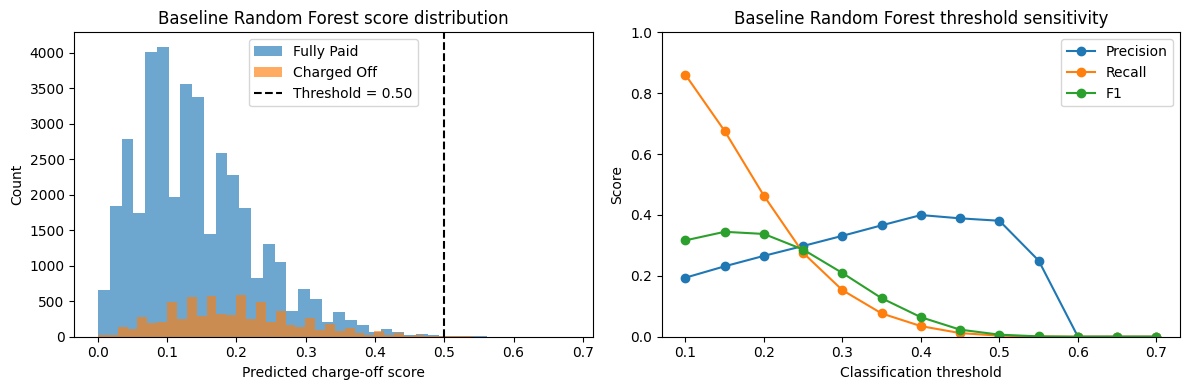

In [5]:
def score_metrics(y_true, prob, threshold=0.50):
    pred = (np.asarray(prob) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'Threshold': float(threshold),
        'Accuracy': accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1-score': f1_score(y_true, pred, zero_division=0),
        'F2-score': fbeta_score(y_true, pred, beta=2, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob),
        'Average Precision': average_precision_score(y_true, prob),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

scan_thresholds = np.round(np.arange(0.10, 0.71, 0.05), 2)
if baseline_predictions is not None:
    rf_prob_col = 'Random Forest_prob'
    assert rf_prob_col in baseline_predictions, f'Missing {rf_prob_col} in saved Part D predictions.'
    rf_base_prob = baseline_predictions[rf_prob_col].to_numpy()
    baseline_rf_scan = pd.DataFrame([
        {'Model': 'Random Forest baseline', **score_metrics(y_val, rf_base_prob, t)}
        for t in scan_thresholds
    ])
    display(baseline_rf_scan[['Threshold','Precision','Recall','F1-score','F2-score','FP','FN','TP']].round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(rf_base_prob[y_val.to_numpy()==0], bins=40, alpha=.65, label='Fully Paid')
    axes[0].hist(rf_base_prob[y_val.to_numpy()==1], bins=40, alpha=.65, label='Charged Off')
    axes[0].axvline(0.50, ls='--', color='black', label='Threshold = 0.50')
    axes[0].set(xlabel='Predicted charge-off score', ylabel='Count',
                title='Baseline Random Forest score distribution')
    axes[0].legend()
    axes[1].plot(baseline_rf_scan['Threshold'], baseline_rf_scan['Precision'], marker='o', label='Precision')
    axes[1].plot(baseline_rf_scan['Threshold'], baseline_rf_scan['Recall'], marker='o', label='Recall')
    axes[1].plot(baseline_rf_scan['Threshold'], baseline_rf_scan['F1-score'], marker='o', label='F1')
    axes[1].set(xlabel='Classification threshold', ylabel='Score', ylim=(0, 1),
                title='Baseline Random Forest threshold sensitivity')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print('Part D probability diagnostic unavailable; the tuning experiment can still continue.')

## 4. Hyperparameters and cross-validation design

**Methods:** `GridSearchCV` for the inexpensive linear model; `RandomizedSearchCV` for the more expensive tree ensembles. Every candidate is evaluated with **3-fold stratified CV**, shuffled with fixed seed 42. Selection is by **mean CV Average Precision**; ROC-AUC, F1, recall and precision are recorded as secondary CV metrics.

**Why these parameters?**

| Model | Investigated parameters | Rationale |
|---|---|---|
| Logistic Regression | `C` | Strength of L2 regularisation; lower `C` means stronger shrinkage. Keep `lbfgs` and `max_iter=1000` fixed as in Part D. |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` | Stability, tree depth, leaf smoothing and feature subsampling, potentially improving minority-class ranking and reducing overfitting. |
| Histogram Gradient Boosting | `learning_rate`, `max_iter`, `max_leaf_nodes`, `l2_regularization` | Trade off boosting step size, number of boosting iterations, tree complexity and regularisation. |

**Fairness:** All models retain the **same computed class weights from the training labels** as Part D; no class-weight tuning, new features or test-set use. HGB uses the same default `early_stopping='auto'` as Part D, so `max_iter` is an upper bound and may not equal actual iterations. Threshold tuning is a separate analysis.

In [6]:
classes = np.array([0, 1])
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

base_estimators = {
    'Logistic Regression': LogisticRegression(
        C=1.0, solver='lbfgs', max_iter=1000,
        class_weight=class_weights, random_state=SEED
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, class_weight=class_weights,
        random_state=SEED, n_jobs=-1
    ),
    'Histogram Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.1, max_leaf_nodes=31,
        class_weight=class_weights, random_state=SEED
    ),
}

lr_grid = {'C': [0.01, 0.1, 1.0, 10.0, 100.0]}
rf_space = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 5, 20, 50],
    'max_features': ['sqrt', 0.5],
}
hgb_space = {
    'learning_rate': [0.03, 0.05, 0.1],
    'max_iter': [100, 180, 300],
    'max_leaf_nodes': [15, 31],
    'l2_regularization': [0.0, 1.0, 10.0],
}
rf_iter = 4 if QUICK_RUN else 10
hgb_iter = 5 if QUICK_RUN else 12
if QUICK_RUN:
    lr_grid = {'C': [0.1, 1.0, 10.0]}

scoring = {
    'average_precision': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
}

searches = {
    'Logistic Regression': GridSearchCV(
        base_estimators['Logistic Regression'], param_grid=lr_grid,
        scoring=scoring, refit=PRIMARY_SCORING, cv=cv,
        n_jobs=1, return_train_score=False, error_score='raise', verbose=1
    ),
    'Random Forest': RandomizedSearchCV(
        base_estimators['Random Forest'], param_distributions=rf_space,
        n_iter=rf_iter, random_state=SEED,
        scoring=scoring, refit=PRIMARY_SCORING, cv=cv,
        n_jobs=1, return_train_score=False, error_score='raise', verbose=1
    ),
    'Histogram Gradient Boosting': RandomizedSearchCV(
        base_estimators['Histogram Gradient Boosting'], param_distributions=hgb_space,
        n_iter=hgb_iter, random_state=SEED,
        scoring=scoring, refit=PRIMARY_SCORING, cv=cv,
        n_jobs=1, return_train_score=False, error_score='raise', verbose=1
    ),
}

search_plan = pd.DataFrame([
    ['Logistic Regression', 'GridSearchCV', len(lr_grid['C'])],
    ['Random Forest', 'RandomizedSearchCV', rf_iter],
    ['Histogram Gradient Boosting', 'RandomizedSearchCV', hgb_iter],
], columns=['Model','Method','Candidate configurations'])
search_plan['CV fits'] = search_plan['Candidate configurations'] * CV_FOLDS
print('Weights (training only):', class_weights)
display(search_plan)
print('Total CV candidate fits:', int(search_plan['CV fits'].sum()),
      '| plus one full-training refit per model.')

Weights (training only): {0: 0.591888227987196, 1: 3.220696714652455}


,Model,Method,Candidate configurations,CV fits
0,Logistic Regression,GridSearchCV,5,15
1,Random Forest,RandomizedSearchCV,10,30
2,Histogram Gradient Boosting,RandomizedSearchCV,12,36


Total CV candidate fits: 81 | plus one full-training refit per model.


## 5. Run optimisation and save each search immediately

Each search reports the **actual** optimal parameters and the mean and standard deviation of the CV score. Results are checkpointed after each model, so the first model's trial results remain saved even if a later model is interrupted. The best estimator is automatically refitted on the full training set, but the validation/test labels play no role in choosing the hyperparameters.

> If Colab stops during the long forest search, the completed `*_cv_trials.csv` and `*_best_parameters.json` files remain available. This notebook does **not** automatically reuse cached search results; rerunning this cell performs a fresh search.

In [7]:
def slug(name):
    return name.lower().replace(' ', '_')

def python_scalar(x):
    if isinstance(x, np.generic):
        return x.item()
    return x

best_models = {}
search_summaries = []
all_trials = []
search_objects = {}

for name in MODEL_NAMES:
    print('\n' + '=' * 70)
    print('TUNING:', name)
    search = searches[name]
    started = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - started

    best_models[name] = search.best_estimator_
    search_objects[name] = search
    cv_trials = pd.DataFrame(search.cv_results_)
    cv_trials.insert(0, 'Model', name)
    cv_trials.to_csv(OUT / f'{slug(name)}_cv_trials.csv', index=False)
    all_trials.append(cv_trials)

    idx = search.best_index_
    params = {k: python_scalar(v) for k, v in search.best_params_.items()}
    record = {
        'Model': name,
        'Search Method': type(search).__name__,
        'Candidates': len(cv_trials),
        'CV Folds': CV_FOLDS,
        'Best CV Average Precision': float(search.best_score_),
        'CV AP Std': float(cv_trials.loc[idx, 'std_test_average_precision']),
        'Best CV ROC-AUC': float(cv_trials.loc[idx, 'mean_test_roc_auc']),
        'Best CV F1 @0.50': float(cv_trials.loc[idx, 'mean_test_f1']),
        'Mean Fit Time per CV Fold (s)': float(cv_trials.loc[idx, 'mean_fit_time']),
        'Full-Training Refit Time (s)': float(search.refit_time_),
        'Total Search Time (s)': elapsed,
        'Best Parameters': json.dumps(params, sort_keys=True),
    }
    search_summaries.append(record)
    (OUT / f'{slug(name)}_best_parameters.json').write_text(
        json.dumps({'model': name, 'best_params': params,
                    'best_cv_average_precision': record['Best CV Average Precision'],
                    'cv_folds': CV_FOLDS, 'seed': SEED,
                    'quick_run': QUICK_RUN}, indent=2)
    )
    pd.DataFrame(search_summaries).to_csv(OUT / 'best_hyperparameters.csv', index=False)
    print('Best params:', params)
    print('Mean CV AP:', f'{search.best_score_:.5f}',
          '+/-', f'{record["CV AP Std"]:.5f}')
    print('Total search time (s):', f'{elapsed:.1f}')

pd.concat(all_trials, ignore_index=True, sort=False).to_csv(
    OUT / 'hyperparameter_search_results.csv', index=False
)
best_params_df = pd.DataFrame(search_summaries).set_index('Model')
display(best_params_df[['Search Method','Candidates','Best CV Average Precision',
                        'CV AP Std','Best CV ROC-AUC','Best CV F1 @0.50',
                        'Total Search Time (s)','Best Parameters']])


TUNING: Logistic Regression
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best params: {'C': 0.1}
Mean CV AP: 0.28787 +/- 0.00043
Total search time (s): 62.0

TUNING: Random Forest
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'n_estimators': 150, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 20}
Mean CV AP: 0.28609 +/- 0.00262
Total search time (s): 3274.3

TUNING: Histogram Gradient Boosting
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best params: {'max_leaf_nodes': 15, 'max_iter': 180, 'learning_rate': 0.05, 'l2_regularization': 10.0}
Mean CV AP: 0.29135 +/- 0.00110
Total search time (s): 481.7


,Search Method,Candidates,Best CV Average Precision,CV AP Std,Best CV ROC-AUC,Best CV F1 @0.50,Total Search Time (s),Best Parameters
Model,,,,,,,,
Logistic Regression,GridSearchCV,5,0.287867,0.000431,0.694617,0.357078,62.006101,"{""C"": 0.1}"
Random Forest,RandomizedSearchCV,10,0.286086,0.002622,0.693643,0.356796,3274.347751,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""min..."
Histogram Gradient Boosting,RandomizedSearchCV,12,0.291345,0.001097,0.697334,0.356644,481.699238,"{""l2_regularization"": 10.0, ""learning_rate"": 0..."


## 6. Evaluate tuned models at **the original threshold (0.50)**

This is the cleanest comparison against Part D. We use exactly the same holdout validation rows and metrics. A positive change in Average Precision/ROC-AUC indicates improved *ranking*; F1/recall/precision at 0.50 indicate improved *classification decisions*. These can move in opposite directions.

A hyperparameter search can legitimately produce worse validation performance. Report decreases rather than hiding them.

In [8]:
tuned_predictions = pd.DataFrame({'actual': y_val.to_numpy()})
validation_records = []
train_records = []

for name in MODEL_NAMES:
    model = best_models[name]
    prob_val = model.predict_proba(X_val)[:, 1]
    prob_train = model.predict_proba(X_train)[:, 1]
    pred_val = (prob_val >= 0.50).astype(int)

    tuned_predictions[f'{name}_prob'] = prob_val
    tuned_predictions[f'{name}_pred'] = pred_val

    val_metrics = score_metrics(y_val, prob_val, threshold=0.50)
    validation_records.append({
        'Model': name,
        **val_metrics,
        'Training Time (s)': float(search_objects[name].refit_time_),
    })
    train_records.append({
        'Model': name,
        'Train F1 @0.50': f1_score(y_train, (prob_train >= .50).astype(int), zero_division=0),
        'Train Average Precision': average_precision_score(y_train, prob_train),
        'Validation F1 @0.50': val_metrics['F1-score'],
        'Validation Average Precision': val_metrics['Average Precision'],
    })

optimized_metrics = pd.DataFrame(validation_records).set_index('Model').loc[MODEL_NAMES]
optimized_metrics.reset_index().to_csv(OUT / 'optimised_metrics.csv', index=False)
tuned_predictions.to_csv(OUT / 'optimised_validation_predictions.csv', index=False)
pd.DataFrame(train_records).to_csv(OUT / 'train_validation_diagnostics.csv', index=False)

metric_cols = ['Accuracy','Precision','Recall','F1-score','F2-score','ROC-AUC','Average Precision']
display(optimized_metrics[metric_cols + ['TN','FP','FN','TP','Training Time (s)']].round(4))
print('In-sample training versus held-out validation (diagnostic only):')
display(pd.DataFrame(train_records).set_index('Model').round(4))

,Accuracy,Precision,Recall,F1-score,F2-score,ROC-AUC,Average Precision,TN,FP,FN,TP,Training Time (s)
Model,,,,,,,,,,,,
Logistic Regression,0.6335,0.2458,0.6572,0.3578,0.4924,0.6945,0.2819,24072,14193,2412,4625,3.6546
Random Forest,0.6853,0.2653,0.5799,0.3640,0.4687,0.6975,0.2847,26963,11302,2956,4081,81.4510
Histogram Gradient Boosting,0.6263,0.2437,0.6683,0.3572,0.4956,0.6976,0.2861,23670,14595,2334,4703,20.7265


In-sample training versus held-out validation (diagnostic only):


,Train F1 @0.50,Train Average Precision,Validation F1 @0.50,Validation Average Precision
Model,,,,
Logistic Regression,0.3579,0.2886,0.3578,0.2819
Random Forest,0.4430,0.4102,0.3640,0.2847
Histogram Gradient Boosting,0.3669,0.3073,0.3572,0.2861


## 7. Quantify the **hyperparameter-only** change from Part D

The table below holds the classification threshold fixed at 0.50. `Delta` means tuned minus baseline; an improvement is **not guaranteed**. Baseline and tuned training times are not perfectly comparable to total search cost; report search time separately.

In [9]:
rows = []
for name in MODEL_NAMES:
    for metric in metric_cols:
        base = float(baseline_metrics.loc[name, metric])
        tuned = float(optimized_metrics.loc[name, metric])
        rows.append({
            'Model': name, 'Metric': metric,
            'Baseline @0.50': base, 'Tuned @0.50': tuned,
            'Delta': tuned - base,
        })
comparison_long = pd.DataFrame(rows)
comparison_long.to_csv(OUT / 'baseline_vs_tuned.csv', index=False)
print('Hyperparameter-only changes at the fixed 0.50 threshold:')
display(comparison_long.pivot(index='Model', columns='Metric', values='Delta')[metric_cols].round(4))
print('Detailed baseline vs tuned rows:')
display(comparison_long.round(4))

Hyperparameter-only changes at the fixed 0.50 threshold:


Metric,Accuracy,Precision,Recall,F1-score,F2-score,ROC-AUC,Average Precision
Model,,,,,,,
Histogram Gradient Boosting,-0.0076,-0.0023,0.0111,-0.0009,0.0030,0.0004,0.0020
Logistic Regression,-0.0001,-0.0001,-0.0003,-0.0001,-0.0002,0.0000,0.0000
Random Forest,-0.1591,-0.1157,0.5765,0.3573,0.4645,0.0222,0.0239


Detailed baseline vs tuned rows:


,Model,Metric,Baseline @0.50,Tuned @0.50,Delta
0,Logistic Regression,Accuracy,0.6335,0.6335,-0.0001
1,Logistic Regression,Precision,0.2459,0.2458,-0.0001
2,Logistic Regression,Recall,0.6575,0.6572,-0.0003
3,Logistic Regression,F1-score,0.3579,0.3578,-0.0001
4,Logistic Regression,F2-score,0.4926,0.4924,-0.0002
5,Logistic Regression,ROC-AUC,0.6945,0.6945,0.0000
6,Logistic Regression,Average Precision,0.2819,0.2819,0.0000
7,Random Forest,Accuracy,0.8443,0.6853,-0.1591
8,Random Forest,Precision,0.3810,0.2653,-0.1157
9,Random Forest,Recall,0.0034,0.5799,0.5765


## 8. Classification threshold analysis (**separate** from hyperparameter optimisation)

Changing the decision threshold does **not** change the fitted model, ROC-AUC or AP. This section scans interpretable thresholds and determines a data-driven **F1-maximising threshold** on the validation set for each tuned model.

**Important limitation:** because thresholds are chosen *using the validation labels*, the displayed validation F1 at the selected threshold is **optimistically selected**. Do not present it as an independent final result; evaluate the locked thresholds **once on the untouched test set in Part G**. The original fixed-0.50 comparison above remains the evidence for hyperparameter tuning.

Tuned model threshold choices (selected for F1 on validation, not independent testing):


,Model,Rule,Threshold,Precision,Recall,F1-score,F2-score,FP,FN,TP
0,Logistic Regression,Fixed threshold,0.5000,0.2458,0.6572,0.3578,0.4924,14193,2412,4625
1,Logistic Regression,Selected by validation F1,0.5349,0.2599,0.5870,0.3603,0.4690,11764,2906,4131
2,Random Forest,Fixed threshold,0.5000,0.2653,0.5799,0.3640,0.4687,11302,2956,4081
3,Random Forest,Selected by validation F1,0.5030,0.2683,0.5761,0.3661,0.4686,11058,2983,4054
4,Histogram Gradient Boosting,Fixed threshold,0.5000,0.2437,0.6683,0.3572,0.4956,14595,2334,4703
5,Histogram Gradient Boosting,Selected by validation F1,0.5597,0.2720,0.5501,0.3640,0.4567,10359,3166,3871


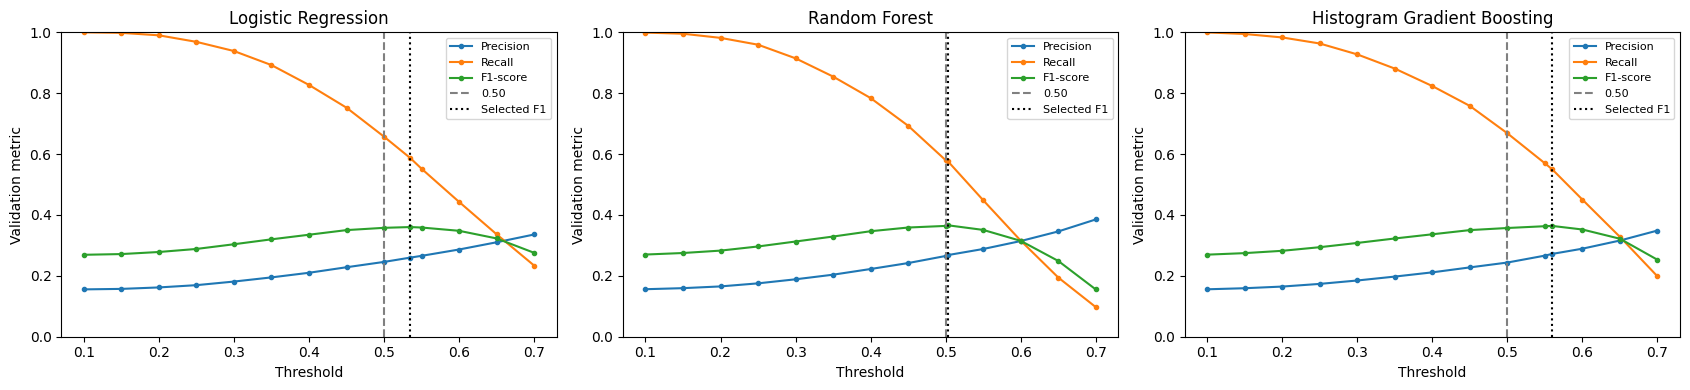

In [10]:
def f1_best_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-12
    )
    valid = np.isfinite(f1_values)
    if not valid.any():
        return 0.50
    best_indices = np.flatnonzero(valid & (f1_values == np.max(f1_values[valid])))
    best_i = best_indices[np.argmin(np.abs(thresholds[best_indices] - .50))]
    return float(thresholds[best_i])

threshold_rows = []
operating_rows = []
selected_thresholds = {}
for name in MODEL_NAMES:
    prob = tuned_predictions[f'{name}_prob'].to_numpy()
    chosen = f1_best_threshold(y_val, prob)
    selected_thresholds[name] = chosen
    for t in sorted(set(scan_thresholds.tolist() + [0.50, chosen])):
        threshold_rows.append({'Model': name, **score_metrics(y_val, prob, t)})
    for label, t in [('Fixed threshold', 0.50), ('Selected by validation F1', chosen)]:
        operating_rows.append({'Model': name, 'Rule': label,
                               **score_metrics(y_val, prob, t)})

threshold_scan = pd.DataFrame(threshold_rows)
threshold_choices = pd.DataFrame(operating_rows)
threshold_scan.to_csv(OUT / 'threshold_analysis.csv', index=False)
threshold_choices.to_csv(OUT / 'threshold_selected_metrics.csv', index=False)
print('Tuned model threshold choices (selected for F1 on validation, not independent testing):')
display(threshold_choices[['Model','Rule','Threshold','Precision','Recall',
                           'F1-score','F2-score','FP','FN','TP']].round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, MODEL_NAMES):
    dat = threshold_scan.loc[threshold_scan['Model'] == name].sort_values('Threshold')
    for metric in ['Precision','Recall','F1-score']:
        ax.plot(dat['Threshold'], dat[metric], marker='.', label=metric)
    ax.axvline(.50, ls='--', color='gray', label='0.50')
    ax.axvline(selected_thresholds[name], ls=':', color='black', label='Selected F1')
    ax.set(title=name, xlabel='Threshold', ylabel='Validation metric', ylim=(0, 1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Visual comparison (tuned models, fixed threshold 0.50)

Confusion matrices and ROC/precision–recall curves use the **same validation partition**. We plot the fixed threshold confusion matrices because those are directly comparable with Part D, while ROC and PR curves are threshold-independent.

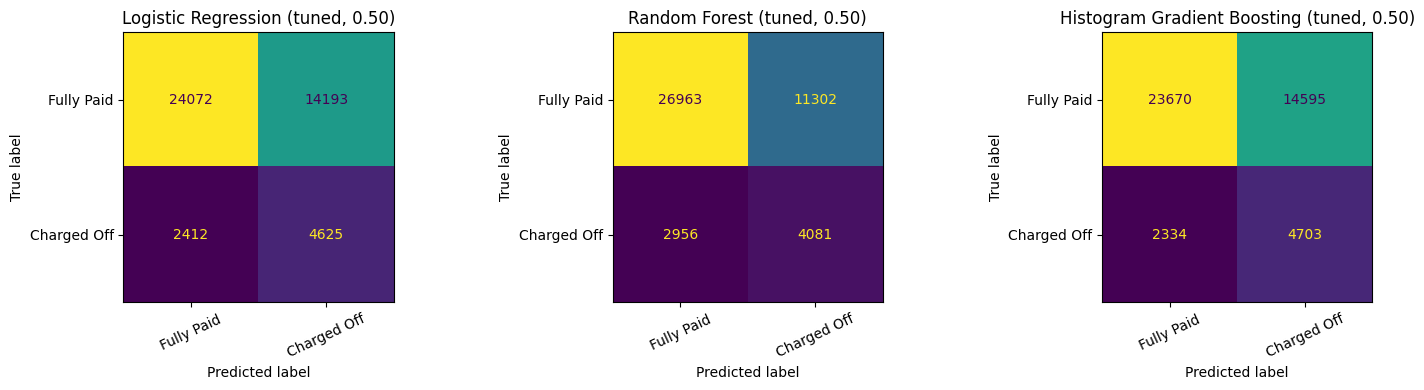

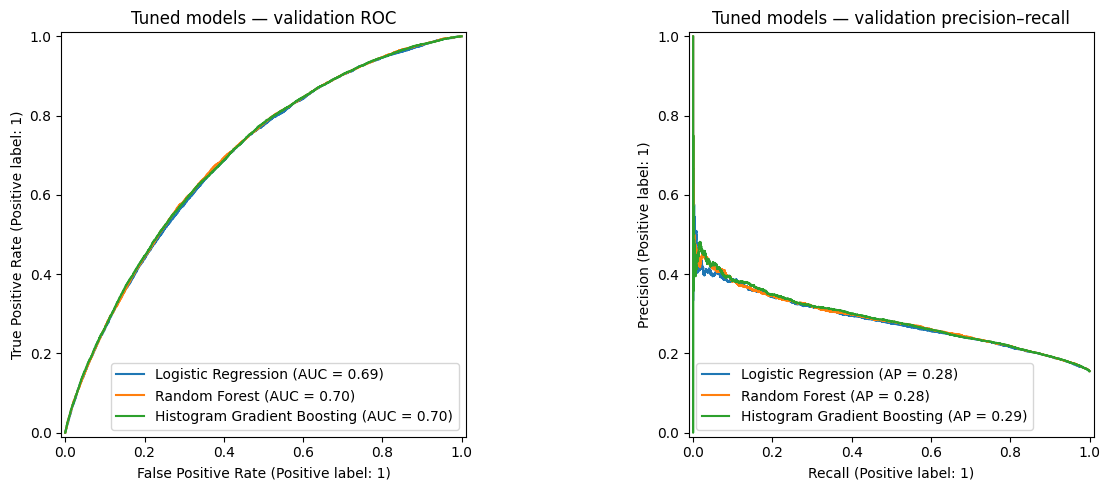

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay.from_predictions(
        y_val, tuned_predictions[f'{name}_pred'],
        labels=[0, 1], display_labels=['Fully Paid', 'Charged Off'],
        ax=ax, colorbar=False, values_format='d'
    )
    ax.set_title(name + ' (tuned, 0.50)')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in MODEL_NAMES:
    prob = tuned_predictions[f'{name}_prob'].to_numpy()
    RocCurveDisplay.from_predictions(y_val, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, prob, name=name, ax=axes[1])
axes[0].set_title('Tuned models — validation ROC')
axes[1].set_title('Tuned models — validation precision–recall')
plt.tight_layout()
plt.show()

## 10. Save model configurations and reproducibility metadata for Parts F and G

- **Parts F/G can read the saved parameters and holdout predictions** without relying on notebook memory.
- The `model_configurations.json` file records the fixed Part D estimator settings, best hyperparameters, selected validation threshold and selection policy.
- Optional model serialization is **off by default** because forest files may be large; enabling it saves fitted estimators to `Part_E_Results/models/`.
- **Do not retrain on the validation or test sets for Part E.** If a later Part G workflow retrains on train+validation, the evaluation procedure must be carefully described and the test must remain strictly untouched.

In [12]:
configurations = {}
for name in MODEL_NAMES:
    configurations[name] = {
        'estimator_class': type(best_models[name]).__name__,
        'fixed_part_d_parameters': {
            k: python_scalar(v)
            for k, v in base_estimators[name].get_params(deep=False).items()
            if k in ('C','solver','max_iter','learning_rate','max_leaf_nodes',
                     'n_estimators','class_weight','random_state','n_jobs')
        },
        'tuned_parameters': {
            k: python_scalar(v) for k, v in search_objects[name].best_params_.items()
        },
        'selection_score': PRIMARY_SCORING,
        'cv_mean_average_precision': float(search_objects[name].best_score_),
        'fixed_threshold': 0.50,
        'validation_f1_selected_threshold': float(selected_thresholds[name]),
    }

metadata = {
    'task': 'Loan charge-off classification (0 Fully Paid; 1 Charged Off)',
    'source': 'Pasted Part D baseline CSV workflow; not older combined D/E notebook',
    'train_path': str(train_path),
    'validation_path': str(val_path),
    'baseline_metrics_path': str(baseline_metrics_path),
    'training_rows': len(y_train),
    'validation_rows': len(y_val),
    'n_features': len(features),
    'features': features,
    'seed': SEED,
    'cv_splits': CV_FOLDS,
    'cv_shuffle': True,
    'cv_selection_metric': PRIMARY_SCORING,
    'quick_run': QUICK_RUN,
    'class_weights': class_weights,
    'threshold_criterion': 'Maximum validation F1, separate from parameter optimisation',
    'test_used': False,
    'sklearn_version': sklearn.__version__,
}

(OUT / 'model_configurations.json').write_text(json.dumps(configurations, indent=2))
(OUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2))

if SAVE_FITTED_MODELS:
    import joblib
    model_dir = OUT / 'models'
    model_dir.mkdir(exist_ok=True)
    for name in MODEL_NAMES:
        fname = model_dir / f'{slug(name)}_tuned.joblib'
        joblib.dump(best_models[name], fname, compress=3)
        print('Saved fitted model:', fname)

print('Saved outputs:')
for file in sorted(OUT.glob('*')):
    print(' -', file.name)

Saved outputs:
 - baseline_vs_tuned.csv
 - best_hyperparameters.csv
 - histogram_gradient_boosting_best_parameters.json
 - histogram_gradient_boosting_cv_trials.csv
 - hyperparameter_search_results.csv
 - logistic_regression_best_parameters.json
 - logistic_regression_cv_trials.csv
 - model_configurations.json
 - optimised_metrics.csv
 - optimised_validation_predictions.csv
 - random_forest_best_parameters.json
 - random_forest_cv_trials.csv
 - run_metadata.json
 - threshold_analysis.csv
 - threshold_selected_metrics.csv
 - train_validation_diagnostics.csv


## 11. Report-ready findings summary (generated from actual run results)

The printed summary is based on the executed search results, not predicted improvements. Cite the actual parameter search table, CV statistics, and baseline/tuned validation deltas in your Part E report. **Avoid claiming statistical significance** without appropriate repeated evaluation and uncertainty analysis.

In [13]:
report_lines = [
    '# Part E — Hyperparameter Optimisation (automatic run summary)',
    '',
    f'- Dataset: {len(y_train):,} training rows, {len(y_val):,} validation rows, {len(features)} features.',
    f'- CV: {CV_FOLDS}-fold stratified, shuffled (random_state={SEED}); primary score = {PRIMARY_SCORING}.',
    f'- Search mode: {"Quick trial" if QUICK_RUN else "Full planned search"}.',
    '- Data processing and class weights are held consistent with the supplied Part D baseline.',
    '- Part G test data was not accessed.',
    '',
    '## Per-model findings at decision threshold 0.50',
]
for name in MODEL_NAMES:
    p = search_objects[name].best_params_
    report_lines += [
        '', f'### {name}',
        f'- Search: {type(search_objects[name]).__name__}; best parameters: `{p}`.',
        f'- Best mean CV Average Precision: {search_objects[name].best_score_:.4f}.',
    ]
    for metric in ['Average Precision','ROC-AUC','F1-score','Precision','Recall']:
        base = float(baseline_metrics.loc[name, metric])
        tuned = float(optimized_metrics.loc[name, metric])
        report_lines.append(
            f'- {metric}: {base:.4f} → {tuned:.4f} '
            f'(change {tuned-base:+.4f}, validation at 0.50).'
        )
    report_lines += [
        f'- Selected validation F1 threshold: {selected_thresholds[name]:.4f} '
        '(exploratory; must be evaluated on untouched test data).',
    ]
report_lines += [
    '',
    '## Interpretation cautions',
    '- CV scores select hyperparameters on training data; validation scores are separate holdout checks.',
    '- Validation threshold selection makes threshold-adjusted validation performance optimistic.',
    '- A decrease in a metric is still a valid experimental result and must be reported.',
    '- Average Precision and ROC-AUC do not change merely because the decision threshold changes.',
    '- Search wall-clock time includes CV fits; refit time measures only final training.',
    '- Fairness/deployment suitability needs further analysis in Part G.',
]
report_path = OUT / 'part_e_report_summary.md'
report_path.write_text('\n'.join(report_lines) + '\n')
print('\n'.join(report_lines))
print('\nReport summary saved:', report_path)

# Part E — Hyperparameter Optimisation (automatic run summary)

- Dataset: 198,221 training rows, 45,302 validation rows, 66 features.
- CV: 3-fold stratified, shuffled (random_state=42); primary score = average_precision.
- Search mode: Full planned search.
- Data processing and class weights are held consistent with the supplied Part D baseline.
- Part G test data was not accessed.

## Per-model findings at decision threshold 0.50

### Logistic Regression
- Search: GridSearchCV; best parameters: `{'C': 0.1}`.
- Best mean CV Average Precision: 0.2879.
- Average Precision: 0.2819 → 0.2819 (change +0.0000, validation at 0.50).
- ROC-AUC: 0.6945 → 0.6945 (change +0.0000, validation at 0.50).
- F1-score: 0.3579 → 0.3578 (change -0.0001, validation at 0.50).
- Precision: 0.2459 → 0.2458 (change -0.0001, validation at 0.50).
- Recall: 0.6575 → 0.6572 (change -0.0003, validation at 0.50).
- Selected validation F1 threshold: 0.5349 (exploratory; must be evaluated on untouched test data).

###